# Phần 3  Canny phát hiện cạnh cho biên đường

Notebook thực hiện phần việc Canny: tự cài Canny bằng NumPy, so với `cv2.Canny`, chạy lưới tham số, thử theo điều kiện ánh sáng và thử ngưỡng tự động.

Đầu vào là ảnh xám đã tiền xử lý HSV ở `outputs/preprocessed_for_canny/canny_input`. Đầu ra là ảnh cạnh nhị phân cho bước ROI và Hough ở `outputs/canny/edges`.

**Phạm vi.** Notebook không đánh giá qua pipeline ROI và Hough. Các chỉ số ở đây chỉ đo riêng Canny, dùng để so sánh tham số, và không phải kết luận cuối.

## Cách dùng trên Google Colab

1. Tải thư mục dự án lên Google Drive, ví dụ `MyDrive/Bai_Tap_Lon`.
2. Bỏ dấu `#` ở hai dòng mount Drive trong ô đầu tiên.
3. Chạy lần lượt các ô.

In [1]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# from google.colab import drive
# drive.mount('/content/drive')

candidates = [Path.cwd(), Path('/content/Bai_Tap_Lon'), Path('/content/drive/MyDrive/Bai_Tap_Lon')]
ROOT = next((p for p in candidates if (p / 'outputs' / 'preprocessed_for_canny').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError('Không tìm thấy outputs/preprocessed_for_canny')

INPUT = ROOT / 'outputs' / 'preprocessed_for_canny'
OUT = ROOT / 'outputs' / 'canny'
FIG = OUT / 'figures'
FIG.mkdir(parents=True, exist_ok=True)

GROUPS = ['normal', 'curved', 'adverse']
NAMES = [(g, p.stem) for g in GROUPS for p in sorted((INPUT / 'canny_input' / g).glob('*.png'))]
print(len(NAMES), 'ảnh')

50 ảnh


## 1. Canny tự cài bằng NumPy

Bốn bước: lọc Gauss, gradient Sobel, loại điểm không cực đại (NMS), ngưỡng kép với hysteresis.

In [2]:
def gaussian_smooth(img, size=5, sigma=1.4):
    ax = np.arange(size) - size // 2
    k = np.exp(-(ax ** 2) / (2 * sigma ** 2))
    k /= k.sum()
    r = size // 2
    p = np.pad(img.astype(np.float64), r, mode='reflect')
    h, w = img.shape
    tmp = sum(k[i] * p[:, i:i + w] for i in range(size))
    return sum(k[i] * tmp[i:i + h, :] for i in range(size))


def sobel_gradient(img, l2=True):
    h, w = img.shape
    p = np.pad(img, 1, mode='reflect')
    a = lambda dy, dx: p[1 + dy:1 + dy + h, 1 + dx:1 + dx + w]
    gx = (a(-1, 1) + 2 * a(0, 1) + a(1, 1)) - (a(-1, -1) + 2 * a(0, -1) + a(1, -1))
    gy = (a(1, -1) + 2 * a(1, 0) + a(1, 1)) - (a(-1, -1) + 2 * a(-1, 0) + a(-1, 1))
    mag = np.hypot(gx, gy) if l2 else np.abs(gx) + np.abs(gy)
    return mag, np.arctan2(gy, gx)


def non_max_suppression(mag, theta):
    h, w = mag.shape
    p = np.pad(mag, 1)
    a = lambda dy, dx: p[1 + dy:1 + dy + h, 1 + dx:1 + dx + w]
    ang = np.rad2deg(theta) % 180
    n1, n2 = np.zeros_like(mag), np.zeros_like(mag)
    for lo, hi, dy, dx in [(0, 22.5, 0, 1), (22.5, 67.5, 1, 1), (67.5, 112.5, 1, 0),
                           (112.5, 157.5, 1, -1), (157.5, 180.01, 0, 1)]:
        m = (ang >= lo) & (ang < hi)
        n1[m] = a(dy, dx)[m]
        n2[m] = a(-dy, -dx)[m]
    return np.where((mag > n1) & (mag >= n2), mag, 0)


def hysteresis(nms, low, high):
    weak = nms >= low
    edges = nms >= high
    h, w = edges.shape
    while True:
        p = np.pad(edges, 1)
        near = np.zeros_like(edges)
        for dy in (-1, 0, 1):
            for dx in (-1, 0, 1):
                near |= p[1 + dy:1 + dy + h, 1 + dx:1 + dx + w]
        new = weak & near
        if (new == edges).all():
            return (edges * 255).astype(np.uint8)
        edges = new


def canny_edges(img, low, high, sigma, size=5, l2=True):
    smooth = gaussian_smooth(img, size, sigma)
    mag, theta = sobel_gradient(smooth, l2)
    return hysteresis(non_max_suppression(mag, theta), low, high)

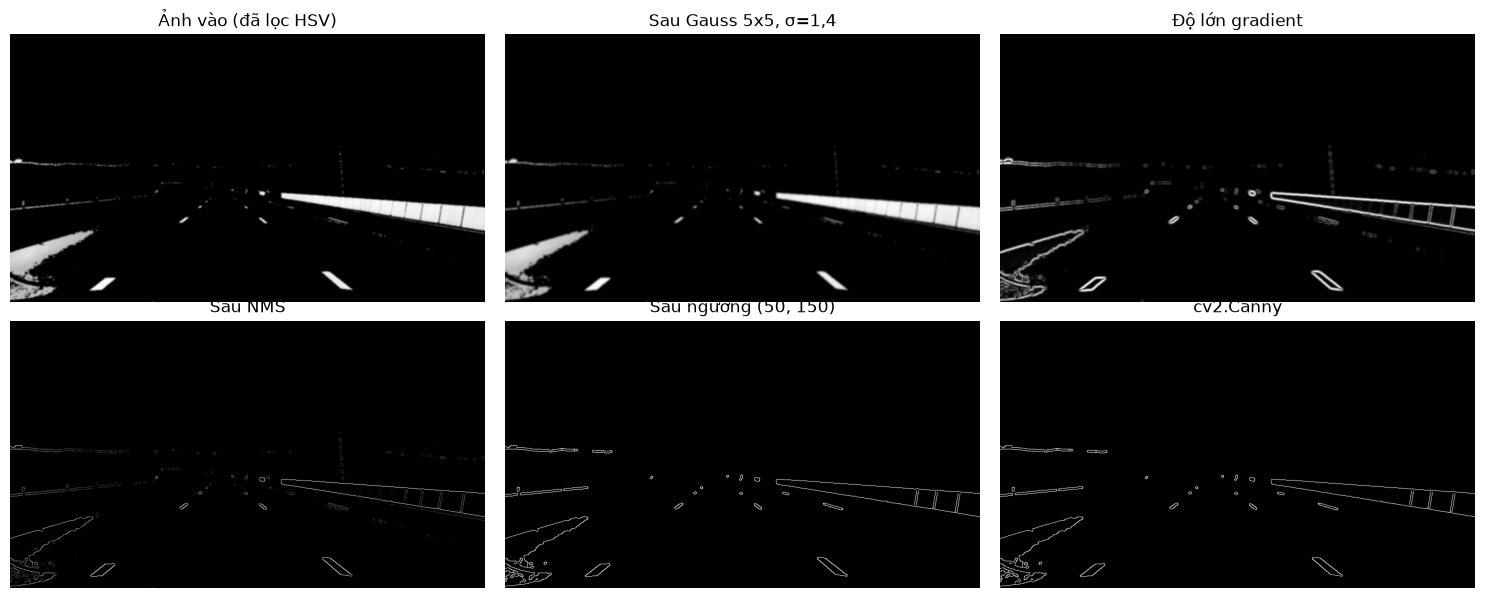

In [3]:
def read_gray(group, name):
    return cv2.imread(str(INPUT / 'canny_input' / group / f'{name}.png'), 0)


def cv_canny(img, low, high, sigma, size=5, l2=True):
    return cv2.Canny(cv2.GaussianBlur(img, (size, size), sigma), low, high, L2gradient=l2)


def iou(a, b):
    a, b = a > 0, b > 0
    return (a & b).sum() / max((a | b).sum(), 1)


img = read_gray('normal', 'normal_05')
smooth = gaussian_smooth(img, 5, 1.4)
mag, theta = sobel_gradient(smooth)
nms = non_max_suppression(mag, theta)
edges = hysteresis(nms, 50, 150)

stages = [(img, 'Ảnh vào (đã lọc HSV)'), (smooth, 'Sau Gauss 5x5, σ=1,4'), (mag, 'Độ lớn gradient'),
          (nms, 'Sau NMS'), (edges, 'Sau ngưỡng (50, 150)'), (cv_canny(img, 50, 150, 1.4), 'cv2.Canny')]
fig, axes = plt.subplots(2, 3, figsize=(15, 6))
for ax, (im, title) in zip(axes.ravel(), stages):
    ax.imshow(im, cmap='gray')
    ax.set_title(title)
    ax.axis('off')
plt.tight_layout()
plt.savefig(FIG / 'canny_stages.png', dpi=130)
plt.show()

In [4]:
scores = [iou(canny_edges(read_gray(g, n), 50, 150, 1.4), cv_canny(read_gray(g, n), 50, 150, 1.4)) for g, n in NAMES]
print('IoU với cv2.Canny: trung bình %.3f, thấp nhất %.3f' % (np.mean(scores), np.min(scores)))

IoU với cv2.Canny: trung bình 0.952, thấp nhất 0.919


## 2. Lưới tham số σ × cặp ngưỡng

Nhân Gauss 5×5, σ ∈ {1,0; 1,4; 2,0}, cặp ngưỡng (thấp, cao) ∈ {(50,100), (50,150), (100,200), (100,300)}.

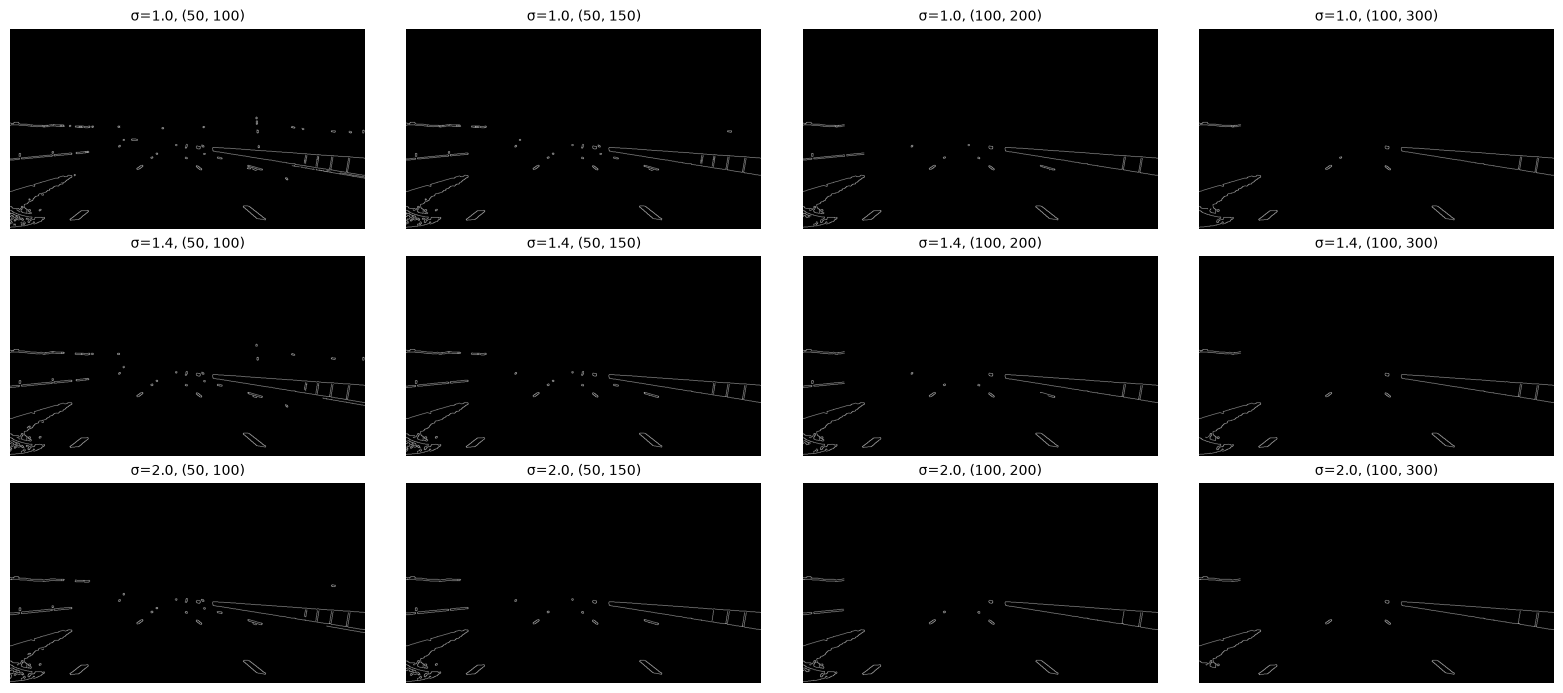

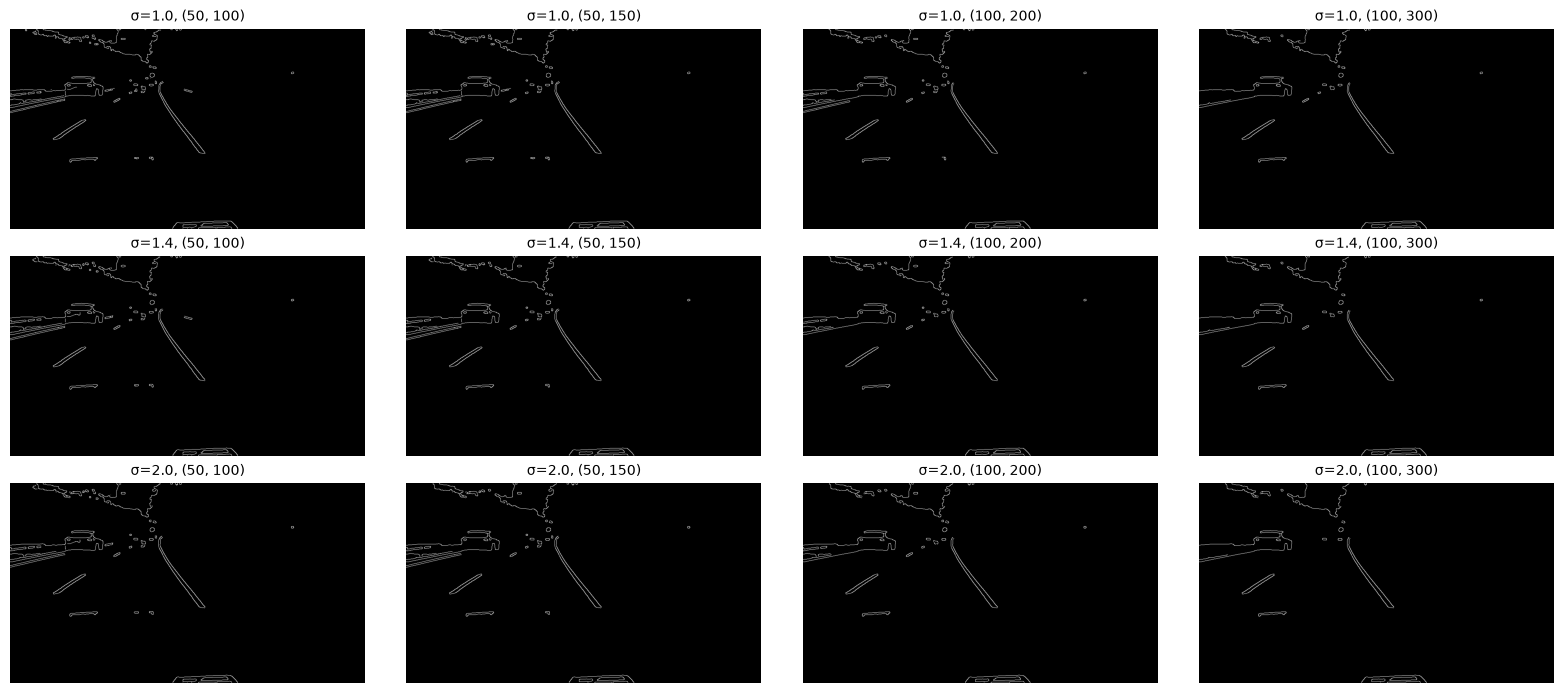

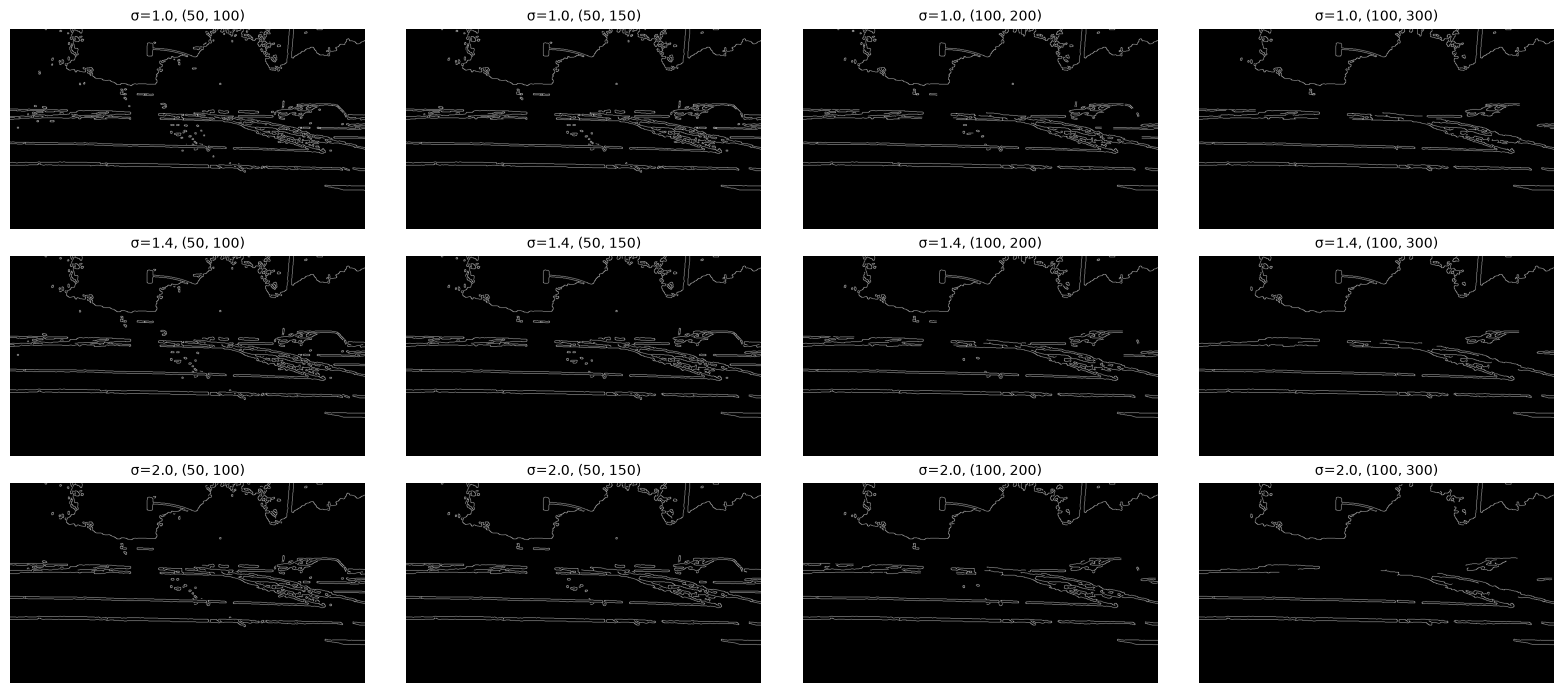

In [5]:
SIGMAS = [1.0, 1.4, 2.0]
PAIRS = [(50, 100), (50, 150), (100, 200), (100, 300)]


def grid_figure(group, name):
    img = read_gray(group, name)
    fig, axes = plt.subplots(len(SIGMAS), len(PAIRS), figsize=(16, 7))
    for i, s in enumerate(SIGMAS):
        for j, (lo, hi) in enumerate(PAIRS):
            axes[i, j].imshow(cv_canny(img, lo, hi, s), cmap='gray')
            axes[i, j].set_title(f'σ={s}, ({lo}, {hi})', fontsize=10)
            axes[i, j].axis('off')
    plt.tight_layout()
    plt.savefig(FIG / f'grid_{name}.png', dpi=110)
    plt.show()


for g, n in [('normal', 'normal_05'), ('curved', 'curved_05'), ('adverse', 'adverse_13')]:
    grid_figure(g, n)

## 3. Thử theo điều kiện ánh sáng

Ground truth là vùng lòng đường. Độ sáng trung bình và độ lệch chuẩn của xám trong vùng này dùng để gán nhãn điều kiện cho từng ảnh:

- **tối**: sáng trung bình dưới 60
- **tương phản cao** (nắng gắt, bóng đổ): độ lệch chuẩn từ 40 trở lên, sáng trung bình từ 60
- **sáng**: sáng trung bình trên 110, độ lệch chuẩn dưới 40
- **vừa**: các ảnh còn lại

Chỉ số đo riêng Canny: **recall** là tỉ lệ điểm trên đường biên vùng lòng đường có cạnh Canny trong 5 pixel, **density** là tỉ lệ pixel cạnh trên toàn ảnh. Precision không dùng để kết luận vì cạnh của vạch kẻ nằm trong lòng đường cũng bị tính là sai.

In [6]:
W, H, TOL = 960, 540, 5
KERNEL = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * TOL + 1, 2 * TOL + 1))


def read_gt(group, name):
    gt = cv2.imread(str(ROOT / 'dataset' / 'ground_truth' / group / f'{name}.png'), 0)
    return cv2.resize(gt, (W, H), interpolation=cv2.INTER_NEAREST) > 0


def gt_boundary(gt):
    b = cv2.morphologyEx(gt.astype(np.uint8), cv2.MORPH_GRADIENT, np.ones((3, 3), np.uint8)) > 0
    b[:8], b[-8:], b[:, :8], b[:, -8:] = False, False, False, False
    return b


def recall_density(edges, boundary):
    e = edges > 0
    near_edge = cv2.dilate(e.astype(np.uint8), KERNEL) > 0
    return (boundary & near_edge).sum() / max(boundary.sum(), 1), e.mean()


def plain_gray(group, name):
    rgb = cv2.imread(str(INPUT / 'resized' / group / f'{name}.png'))
    return cv2.GaussianBlur(cv2.cvtColor(rgb, cv2.COLOR_BGR2GRAY), (0, 0), 1.2)


def condition(group, name):
    gray = cv2.cvtColor(cv2.imread(str(INPUT / 'resized' / group / f'{name}.png')), cv2.COLOR_BGR2GRAY)
    road = gray[read_gt(group, name)]
    mean, std = road.mean(), road.std()
    if mean < 60:
        return 'tối', mean, std
    if std >= 40:
        return 'tương phản cao', mean, std
    if mean > 110:
        return 'sáng', mean, std
    return 'vừa', mean, std


cond = pd.DataFrame([(g, n, *condition(g, n)) for g, n in NAMES], columns=['group', 'name', 'condition', 'mean', 'std'])
cond.to_csv(OUT / 'conditions.csv', index=False)
pd.crosstab(cond['group'], cond['condition'])

condition,sáng,tương phản cao,tối,vừa
group,,,,
adverse,2,6,8,4
curved,1,4,3,4
normal,4,5,2,7


## 4. Chạy toàn bộ tập: ngưỡng cố định

Chạy σ × nhân Gauss (5×5 và 7×7) × 4 cặp ngưỡng trên 50 ảnh, với hai loại đầu vào: ảnh đã lọc HSV và ảnh xám thường (không lọc màu).

In [7]:
data = {}
for g, n in NAMES:
    data[(g, n)] = dict(hsv=read_gray(g, n), plain=plain_gray(g, n), boundary=gt_boundary(read_gt(g, n)))

rows = []
for (g, n), d in data.items():
    c = cond.loc[cond['name'] == n, 'condition'].item()
    for src in ('hsv', 'plain'):
        for s in SIGMAS:
            for k in (5, 7):
                for lo, hi in PAIRS:
                    r, den = recall_density(cv_canny(d[src], lo, hi, s, k), d['boundary'])
                    rows.append(dict(group=g, name=n, condition=c, input=src, method='fixed',
                                     sigma=s, ksize=k, pair=f'({lo}, {hi})', recall=r, density=den))
fixed = pd.DataFrame(rows)
fixed.to_csv(OUT / 'fixed_results.csv', index=False)

hsv_fixed = fixed[fixed['input'] == 'hsv']
print('Ảnh lọc HSV, theo cặp ngưỡng và σ (kernel 5x5)')
hsv_fixed[hsv_fixed['ksize'] == 5].pivot_table(index='pair', columns='sigma', values=['recall', 'density']).round(3)

Ảnh lọc HSV, theo cặp ngưỡng và σ (kernel 5x5)


density               recall              
sigma          1.0    1.4    2.0    1.0    1.4    2.0
pair                                                 
(100, 200)   0.019  0.017  0.016  0.260  0.245  0.231
(100, 300)   0.015  0.012  0.010  0.220  0.191  0.152
(50, 100)    0.024  0.023  0.022  0.312  0.302  0.297
(50, 150)    0.022  0.021  0.019  0.291  0.277  0.271

In [8]:
print('So kernel 5x5 và 7x7 (ảnh lọc HSV, σ=1,4)')
hsv_fixed[hsv_fixed['sigma'] == 1.4].pivot_table(index='pair', columns='ksize', values=['recall', 'density']).round(3)

So kernel 5x5 và 7x7 (ảnh lọc HSV, σ=1,4)


density        recall       
ksize            5      7      5      7
pair                                   
(100, 200)   0.017  0.016  0.245  0.233
(100, 300)   0.012  0.010  0.191  0.156
(50, 100)    0.023  0.022  0.302  0.296
(50, 150)    0.021  0.020  0.277  0.271

In [9]:
rows = []
for (g, n), d in data.items():
    s = cv2.GaussianBlur(d['hsv'], (5, 5), 1.4)
    for aperture in (3, 5):
        for l2 in (False, True):
            r, den = recall_density(cv2.Canny(s, 50, 150, apertureSize=aperture, L2gradient=l2), d['boundary'])
            rows.append(dict(aperture=aperture, L2gradient=l2, recall=r, density=den))
pd.DataFrame(rows).groupby(['aperture', 'L2gradient']).mean().round(3)

recall  density
aperture L2gradient                 
3        False        0.296    0.023
         True         0.277    0.021
5        False        0.354    0.034
         True         0.353    0.033

## 5. Cặp ngưỡng theo điều kiện

Với mỗi điều kiện, chọn cấu hình có recall cao nhất mà density không vượt 2,5% (giới hạn giả định để Hough không bị quá nhiều điểm). Đây là gợi ý tạm thời, cần kiểm tra lại bằng pipeline ROI và Hough.

In [10]:
DENSITY_MAX = 0.025

table = hsv_fixed.groupby(['condition', 'sigma', 'ksize', 'pair'])[['recall', 'density']].mean().reset_index()
best = (table[table['density'] <= DENSITY_MAX].sort_values('recall', ascending=False)
        .groupby('condition').head(1).set_index('condition'))
best['số ảnh'] = cond['condition'].value_counts()
best.round(3).to_csv(OUT / 'best_fixed_by_condition.csv')
best.round(3)

,sigma,ksize,pair,recall,density,số ảnh
condition,,,,,,
sáng,2.0,7,"(50, 150)",0.600,0.025,7
tương phản cao,2.0,7,"(50, 100)",0.368,0.025,15
vừa,1.0,5,"(50, 100)",0.223,0.022,15
tối,1.0,5,"(50, 100)",0.117,0.012,13


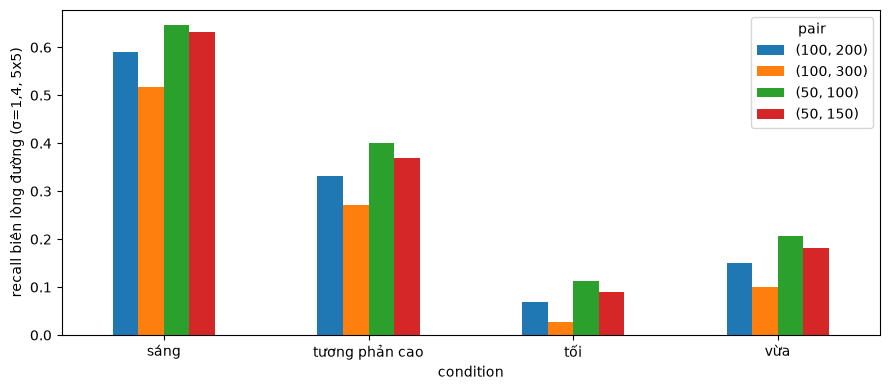

In [11]:
pivot = hsv_fixed[(hsv_fixed['ksize'] == 5) & (hsv_fixed['sigma'] == 1.4)].pivot_table(
    index='condition', columns='pair', values='recall')
pivot.plot(kind='bar', figsize=(9, 4), rot=0)
plt.ylabel('recall biên lòng đường (σ=1,4, 5x5)')
plt.tight_layout()
plt.savefig(FIG / 'recall_by_condition.png', dpi=130)
plt.show()

## 6. Ngưỡng tự động

- Theo trung vị: thấp = 0,67 × median, cao = 1,33 × median (median tính trên pixel khác 0 vì ảnh lọc HSV có nhiều nền đen).
- Theo Otsu: cao = ngưỡng Otsu, thấp = 0,5 × cao.

So sánh với ngưỡng cố định (50, 150) và (100, 200) trên cả hai loại đầu vào, σ = 1,4.

In [12]:
def auto_median(img):
    nz = img[img > 0]
    m = float(np.median(nz)) if nz.size else 0.0
    return 0.67 * m, 1.33 * m


def auto_otsu(img):
    t, _ = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return 0.5 * t, t


rows = []
for (g, n), d in data.items():
    c = cond.loc[cond['name'] == n, 'condition'].item()
    for src in ('hsv', 'plain'):
        s = cv2.GaussianBlur(d[src], (5, 5), 1.4)
        methods = {'cố định (50, 150)': (50, 150), 'cố định (100, 200)': (100, 200),
                   'median': auto_median(s), 'Otsu': auto_otsu(s)}
        for name, (lo, hi) in methods.items():
            r, den = recall_density(cv2.Canny(s, lo, hi, L2gradient=True), d['boundary'])
            rows.append(dict(group=g, condition=c, input=src, method=name, low=lo, high=hi, recall=r, density=den))
auto = pd.DataFrame(rows)
auto.to_csv(OUT / 'auto_results.csv', index=False)
auto.groupby(['input', 'method'])[['low', 'high', 'recall', 'density']].mean().round(3)

low     high  recall  density
input method                                               
hsv   Otsu                 45.560   91.120   0.309    0.024
      cố định (100, 200)  100.000  200.000   0.245    0.017
      cố định (50, 150)    50.000  150.000   0.277    0.021
      median               71.476  141.884   0.284    0.021
plain Otsu                 56.010  112.020   0.390    0.023
      cố định (100, 200)  100.000  200.000   0.149    0.008
      cố định (50, 150)    50.000  150.000   0.314    0.018
      median               54.672  108.528   0.431    0.025

In [13]:
auto[auto['input'] == 'hsv'].pivot_table(index='condition', columns='method', values='recall').round(3)

method,Otsu,"cố định (100, 200)","cố định (50, 150)",median
condition,,,,
sáng,0.649,0.591,0.632,0.603
tương phản cao,0.405,0.332,0.369,0.391
tối,0.121,0.068,0.090,0.118
vừa,0.217,0.150,0.182,0.173


In [14]:
auto[auto['input'] == 'hsv'].pivot_table(index='condition', columns='method', values='density').round(4)

method,Otsu,"cố định (100, 200)","cố định (50, 150)",median
condition,,,,
sáng,0.0348,0.0260,0.0313,0.0296
tương phản cao,0.0301,0.0212,0.0262,0.0287
tối,0.0123,0.0083,0.0102,0.0123
vừa,0.0215,0.0158,0.0189,0.0181


In [15]:
spread = auto[auto['input'] == 'hsv'].groupby(['condition', 'method'])['density'].std().unstack().round(4)
print('Độ lệch chuẩn của density giữa các ảnh cùng điều kiện (thấp = ổn định hơn)')
spread

Độ lệch chuẩn của density giữa các ảnh cùng điều kiện (thấp = ổn định hơn)


method,Otsu,"cố định (100, 200)","cố định (50, 150)",median
condition,,,,
sáng,0.0141,0.0099,0.0125,0.0149
tương phản cao,0.0117,0.0073,0.0099,0.0121
tối,0.0063,0.0039,0.0049,0.0079
vừa,0.0116,0.0082,0.0100,0.0119


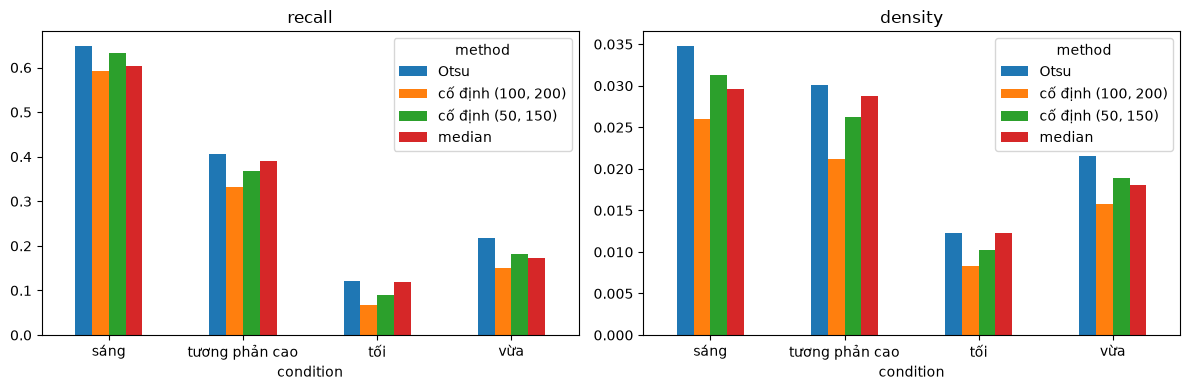

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ['recall', 'density']):
    auto[auto['input'] == 'hsv'].pivot_table(index='condition', columns='method', values=col).plot(kind='bar', ax=ax, rot=0)
    ax.set_title(col)
plt.tight_layout()
plt.savefig(FIG / 'auto_vs_fixed.png', dpi=130)
plt.show()

## 7. Xuất ảnh cạnh cho bước ROI và Hough

Dùng cấu hình mặc định (50, 150), σ = 1,4, nhân 5×5 trên ảnh đã tiền xử lý HSV, ảnh nhị phân 0/255. Cặp ngưỡng gợi ý theo điều kiện nằm ở `best_fixed_by_condition.csv`.

In [17]:
def canny_for_pipeline(img, low=50, high=150, sigma=1.4):
    return canny_edges(img, low, high, sigma)


for g, n in NAMES:
    path = OUT / 'edges' / g / f'{n}.png'
    path.parent.mkdir(parents=True, exist_ok=True)
    cv2.imwrite(str(path), canny_for_pipeline(read_gray(g, n)))
print('Đã ghi', len(NAMES), 'ảnh cạnh vào', OUT / 'edges')

Đã ghi 50 ảnh cạnh vào /home/tdh/Image Processing/Bai_Tap_Lon/outputs/canny/edges
